# Daily & Session Range Analyzer

Historical daily and session range analysis for Candle Fetcher.

## Phase 1 ? Historical Range Analysis

Analyse daily highs, lows, point ranges and percentage ranges for Asia, London and New York.

In [1]:
from pathlib import Path
import sys

# Find the Candle Fetcher project root.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'src').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
from src.range_analysis import calculate_range, calculate_daily_ranges, calculate_session_ranges

print('SUCCESS: Range Analyzer imports loaded!')

SUCCESS: Range Analyzer imports loaded!


In [2]:
# Step 2 ? Load historical candle data

DATA_FOLDER = PROJECT_ROOT / "data" / "processed" / "all_sessions"

available_files = sorted(DATA_FOLDER.glob("*.csv"))

print("Available historical datasets:")
for index, file in enumerate(available_files, start=1):
    print(f"{index}. {file.name}")

# Choose the dataset to analyse.
CSV_FILENAME = "2025_full_year.csv"

csv_path = DATA_FOLDER / CSV_FILENAME

if not csv_path.is_file():
    raise FileNotFoundError(f"Dataset not found: {csv_path}")

df = pd.read_csv(csv_path, parse_dates=["datetime"])

print(f"\nLoaded: {CSV_FILENAME}")
print(f"Candles: {len(df):,}")
print(f"First candle: {df['datetime'].min()}")
print(f"Last candle: {df['datetime'].max()}")

display(df.head())


Available historical datasets:
1. 2023_full_year.csv
2. 2024_full_year.csv
3. 2025_full_year.csv
4. us100_cash_M1_all_sessions_2024_01_01_to_2024_12_31.csv
5. us100_cash_M1_all_sessions_2024_01_01_to_2025_01_01.csv

Loaded: 2025_full_year.csv
Candles: 348,793
First candle: 2025-01-02 01:05:00+00:00
Last candle: 2025-12-31 23:49:00+00:00


,datetime,open,high,low,close,tick_volume,spread,real_volume,session_name
0,2025-01-02 01:05:00+00:00,21100.15,21104.25,21088.65,21093.65,153,290,0,all_sessions
1,2025-01-02 01:06:00+00:00,21093.15,21093.75,21086.05,21091.35,119,290,0,all_sessions
2,2025-01-02 01:07:00+00:00,21091.65,21092.05,21086.15,21088.25,73,290,0,all_sessions
3,2025-01-02 01:08:00+00:00,21088.85,21097.25,21087.25,21096.05,70,290,0,all_sessions
4,2025-01-02 01:09:00+00:00,21098.05,21099.25,21091.75,21092.15,85,290,0,all_sessions


In [3]:

# Step 3 — Calculate historical daily ranges

daily_ranges = calculate_daily_ranges(
    df,
    timezone="UTC"
)

print("DAILY RANGE ANALYSIS — 2025")
print(f"Trading dates found: {len(daily_ranges)}")

display(daily_ranges.head(10))


DAILY RANGE ANALYSIS — 2025
Trading dates found: 258


,trading_date,high,low,candle_count,range_points,range_percent
0,2025-01-02,21273.95,20773.25,1365,500.7,2.4103
1,2025-01-03,21359.25,20936.85,1365,422.4,2.0175
2,2025-01-06,21703.45,21284.85,1365,418.6,1.9667
3,2025-01-07,21616.45,21094.05,1365,522.4,2.4765
4,2025-01-08,21262.95,20981.95,1365,281.0,1.3392
5,2025-01-09,21166.45,21036.95,925,129.5,0.6156
6,2025-01-10,21199.25,20706.15,1365,493.1,2.3814
7,2025-01-13,20868.45,20527.65,1365,340.8,1.6602
8,2025-01-14,20979.15,20611.75,1365,367.4,1.7825
9,2025-01-15,21288.55,20747.15,1365,541.4,2.6095


In [4]:
# Step 4 — Inspect historical daily candle coverage

coverage = (
    daily_ranges["candle_count"]
    .value_counts()
    .sort_index()
    .rename_axis("candles_per_day")
    .reset_index(name="number_of_days")
)

print("DAILY CANDLE COVERAGE — 2025")
display(coverage)

DAILY CANDLE COVERAGE — 2025


,candles_per_day,number_of_days
0,497,1
1,925,1
2,1135,7
3,1150,2
4,1346,1
5,1357,1
6,1364,2
7,1365,243


In [5]:
# Step 5 — Identify dates with reduced candle coverage

EXPECTED_CANDLES = 1365

reduced_coverage = daily_ranges[
    daily_ranges["candle_count"] < EXPECTED_CANDLES
].copy()

reduced_coverage["missing_vs_reference"] = (
    EXPECTED_CANDLES - reduced_coverage["candle_count"]
)

print("DATES WITH REDUCED CANDLE COVERAGE — 2025")
print(f"Number of dates: {len(reduced_coverage)}")

display(
    reduced_coverage[
        [
            "trading_date",
            "candle_count",
            "missing_vs_reference",
            "range_points",
            "range_percent"
        ]
    ]
)

DATES WITH REDUCED CANDLE COVERAGE — 2025
Number of dates: 15


,trading_date,candle_count,missing_vs_reference,range_points,range_percent
5,2025-01-09,925,440,129.50,0.6156
12,2025-01-20,1135,230,249.85,1.1689
32,2025-02-17,1135,230,88.70,0.4012
40,2025-02-27,1364,1,801.19,3.9033
48,2025-03-11,1357,8,542.50,2.8386
64,2025-04-02,1364,1,964.30,5.1014
101,2025-05-26,1135,230,314.50,1.5022
119,2025-06-19,1135,230,306.01,1.4285
129,2025-07-03,1150,215,283.50,1.2535
130,2025-07-04,1135,230,183.01,0.8069


In [6]:
# Step 6 — Classify daily candle coverage

EXPECTED_CANDLES = 1365

daily_ranges["coverage_status"] = daily_ranges[
    "candle_count"
].apply(
    lambda count: (
        "reference_coverage"
        if count == EXPECTED_CANDLES
        else "reduced_coverage"
    )
)

print("DAILY COVERAGE CLASSIFICATION — 2025")

coverage_summary = (
    daily_ranges["coverage_status"]
    .value_counts()
    .rename_axis("coverage_status")
    .reset_index(name="number_of_days")
)

display(coverage_summary)

DAILY COVERAGE CLASSIFICATION — 2025


,coverage_status,number_of_days
0,reference_coverage,243
1,reduced_coverage,15


In [7]:

# Step 7 — Historical daily range statistics

reference_days = daily_ranges[
    daily_ranges["coverage_status"] == "reference_coverage"
].copy()

ranges = reference_days["range_points"]

daily_statistics = pd.DataFrame({
    "Metric": [
        "Trading days",
        "Mean range",
        "Median range (P50)",
        "Minimum range",
        "Maximum range",
        "P10",
        "P25",
        "P75",
        "P90"
    ],
    "Value": [
        len(ranges),
        ranges.mean(),
        ranges.median(),
        ranges.min(),
        ranges.max(),
        ranges.quantile(0.10),
        ranges.quantile(0.25),
        ranges.quantile(0.75),
        ranges.quantile(0.90)
    ]
})

daily_statistics["Value"] = daily_statistics["Value"].round(2)

print("NAS100 — HISTORICAL DAILY RANGE STATISTICS (2025)")
print("Reference-coverage days only")

display(daily_statistics)


NAS100 — HISTORICAL DAILY RANGE STATISTICS (2025)
Reference-coverage days only


,Metric,Value
0,Trading days,243.00
1,Mean range,405.40
2,Median range (P50),346.29
3,Minimum range,100.10
4,Maximum range,2629.54
5,P10,187.82
6,P25,247.04
7,P75,493.10
8,P90,627.03


In [8]:
# Step 8 — Investigate the largest historical daily ranges

largest_days = (
    reference_days
    .sort_values("range_points", ascending=False)
    .head(10)
)

print("TOP 10 LARGEST DAILY RANGES — 2025")

display(
    largest_days[
        [
            "trading_date",
            "high",
            "low",
            "range_points",
            "range_percent",
            "candle_count"
        ]
    ]
)

TOP 10 LARGEST DAILY RANGES — 2025


,trading_date,high,low,range_points,range_percent,candle_count
69,2025-04-09,19234.59,16605.05,2629.54,15.8358,1365
67,2025-04-07,18216.99,16322.45,1894.54,11.6070,1365
70,2025-04-10,19234.89,17776.95,1457.94,8.2013,1365
68,2025-04-08,18218.05,16836.75,1381.30,8.2041,1365
66,2025-04-04,18555.05,17241.19,1313.86,7.6205,1365
229,2025-11-20,25223.15,23997.36,1225.79,5.1080,1365
200,2025-10-10,25199.75,24197.55,1002.20,4.1417,1365
17,2025-01-27,21574.45,20630.95,943.50,4.5732,1365
47,2025-03-10,20118.75,19237.85,880.90,4.5790,1365
79,2025-04-24,19291.86,18482.85,809.01,4.3771,1365


In [9]:

# Step 9 — Inspect the largest daily range

selected_date = "2025-04-09"

day_candles = df[
    df["datetime"].dt.strftime("%Y-%m-%d") == selected_date
].copy()

highest_candle = day_candles.loc[
    day_candles["high"].idxmax()
]

lowest_candle = day_candles.loc[
    day_candles["low"].idxmin()
]

print(f"DAILY RANGE INVESTIGATION — {selected_date}")
print(f"Total candles: {len(day_candles):,}")

print("\nDAILY HIGH")
print(f"Time (UTC): {highest_candle['datetime']}")
print(f"Price: {highest_candle['high']:,.2f}")

print("\nDAILY LOW")
print(f"Time (UTC): {lowest_candle['datetime']}")
print(f"Price: {lowest_candle['low']:,.2f}")

print("\nTOTAL RANGE")
print(
    f"{highest_candle['high'] - lowest_candle['low']:,.2f} points"
)


DAILY RANGE INVESTIGATION — 2025-04-09
Total candles: 1,365

DAILY HIGH
Time (UTC): 2025-04-09 22:55:00+00:00
Price: 19,234.59

DAILY LOW
Time (UTC): 2025-04-09 08:39:00+00:00
Price: 16,605.05

TOTAL RANGE
2,629.54 points


In [10]:

# Step 10 — Calculate historical New York session ranges

ny_ranges = calculate_session_ranges(
    df,
    session_name="new_york"
)

print("NEW YORK SESSION RANGES — 2025")
print(f"Trading dates found: {len(ny_ranges)}")

display(ny_ranges.head(10))


NEW YORK SESSION RANGES — 2025
Trading dates found: 258


,trading_date,session,high,low,candle_count,range_points,range_percent
0,2025-01-02,new_york,21273.95,20951.85,200,322.1,1.5373
1,2025-01-03,new_york,21238.95,21008.45,200,230.5,1.0972
2,2025-01-06,new_york,21693.85,21451.35,200,242.5,1.1305
3,2025-01-07,new_york,21616.45,21336.85,200,279.6,1.3104
4,2025-01-08,new_york,21220.85,21036.25,200,184.6,0.8775
5,2025-01-09,new_york,21155.75,21086.75,140,69.0,0.3272
6,2025-01-10,new_york,21151.95,20706.15,200,445.8,2.1530
7,2025-01-13,new_york,20691.35,20539.25,200,152.1,0.7405
8,2025-01-14,new_york,20971.75,20778.15,200,193.6,0.9317
9,2025-01-15,new_york,21245.75,20816.65,200,429.1,2.0613


In [11]:
# Step 11 — Check New York session candle coverage

ny_coverage = (
    ny_ranges["candle_count"]
    .value_counts()
    .sort_index()
    .rename_axis("candles_per_session")
    .reset_index(name="number_of_sessions")
)

print("NEW YORK SESSION COVERAGE — 2025")
display(ny_coverage)

print(f"\nTotal sessions: {len(ny_ranges)}")
print(
    "Sessions with exactly 200 candles:",
    (ny_ranges["candle_count"] == 200).sum()
)

NEW YORK SESSION COVERAGE — 2025


,candles_per_session,number_of_sessions
0,100,1
1,140,1
2,181,1
3,196,1
4,200,254



Total sessions: 258
Sessions with exactly 200 candles: 254


In [12]:

# Step 12 — New York historical session range statistics

ny_reference = ny_ranges[
    ny_ranges["candle_count"] == 200
].copy()

ny_points = ny_reference["range_points"]

ny_statistics = pd.DataFrame({
    "Metric": [
        "Sessions analysed",
        "Mean range",
        "Median range (P50)",
        "Minimum range",
        "Maximum range",
        "P10",
        "P25",
        "P75",
        "P90"
    ],
    "Value": [
        len(ny_points),
        ny_points.mean(),
        ny_points.median(),
        ny_points.min(),
        ny_points.max(),
        ny_points.quantile(0.10),
        ny_points.quantile(0.25),
        ny_points.quantile(0.75),
        ny_points.quantile(0.90)
    ]
})

ny_statistics["Value"] = ny_statistics["Value"].round(2)

print("NAS100 — NEW YORK SESSION RANGE STATISTICS (2025)")
print("Session: 09:10–12:30 America/New_York")
print("Sessions with 200 candles only")

display(ny_statistics)


NAS100 — NEW YORK SESSION RANGE STATISTICS (2025)
Session: 09:10–12:30 America/New_York
Sessions with 200 candles only


,Metric,Value
0,Sessions analysed,254.00
1,Mean range,161.60
2,Median range (P50),127.30
3,Minimum range,30.50
4,Maximum range,654.10
5,P10,54.64
6,P25,77.93
7,P75,218.02
8,P90,324.76


In [13]:

# Step 13 — Calculate historical London session ranges

london_ranges = calculate_session_ranges(
    df,
    session_name="london"
)

print("LONDON SESSION RANGES — 2025")
print("Session: 08:00–11:00 Europe/London")
print(f"Trading dates found: {len(london_ranges)}")

display(london_ranges.head(10))

print("\nLONDON SESSION CANDLE COVERAGE")

london_coverage = (
    london_ranges["candle_count"]
    .value_counts()
    .sort_index()
    .rename_axis("candles_per_session")
    .reset_index(name="number_of_sessions")
)

display(london_coverage)



LONDON SESSION RANGES — 2025
Session: 08:00–11:00 Europe/London
Trading dates found: 258


,trading_date,session,high,low,candle_count,range_points,range_percent
0,2025-01-02,london,21207.85,21102.35,180,105.5,0.4999
1,2025-01-03,london,21074.75,21010.75,180,64.0,0.3046
2,2025-01-06,london,21429.85,21335.95,180,93.9,0.4401
3,2025-01-07,london,21575.85,21494.65,180,81.2,0.3778
4,2025-01-08,london,21249.65,21175.75,180,73.9,0.3490
5,2025-01-09,london,21147.55,21036.95,180,110.6,0.5257
6,2025-01-10,london,21128.75,21061.45,180,67.3,0.3195
7,2025-01-13,london,20761.15,20629.85,180,131.3,0.6365
8,2025-01-14,london,20979.15,20857.25,180,121.9,0.5844
9,2025-01-15,london,20797.25,20747.15,180,50.1,0.2415



LONDON SESSION CANDLE COVERAGE


,candles_per_session,number_of_sessions
0,2,1
1,180,257


In [14]:

# Step 14 — London historical session range statistics

london_reference = london_ranges[
    london_ranges["candle_count"] == 180
].copy()

london_points = london_reference["range_points"]

london_statistics = pd.DataFrame({
    "Metric": [
        "Sessions analysed",
        "Mean range",
        "Median range (P50)",
        "Minimum range",
        "Maximum range",
        "P10",
        "P25",
        "P75",
        "P90"
    ],
    "Value": [
        len(london_points),
        london_points.mean(),
        london_points.median(),
        london_points.min(),
        london_points.max(),
        london_points.quantile(0.10),
        london_points.quantile(0.25),
        london_points.quantile(0.75),
        london_points.quantile(0.90)
    ]
})

london_statistics["Value"] = london_statistics["Value"].round(2)

print("NAS100 — LONDON SESSION RANGE STATISTICS (2025)")
print("Session: 08:00–11:00 Europe/London")
print("Sessions with 180 candles only")

display(london_statistics)


NAS100 — LONDON SESSION RANGE STATISTICS (2025)
Session: 08:00–11:00 Europe/London
Sessions with 180 candles only


,Metric,Value
0,Sessions analysed,257.00
1,Mean range,80.53
2,Median range (P50),67.30
3,Minimum range,14.80
4,Maximum range,403.50
5,P10,36.66
6,P25,47.10
7,P75,97.30
8,P90,132.54


In [15]:

# Step 15 — Calculate historical Asia session ranges

asia_ranges = calculate_session_ranges(
    df,
    session_name="asia"
)

print("ASIA SESSION RANGES — 2025")
print("Session: 09:00–12:00 Asia/Tokyo")
print(f"Trading dates found: {len(asia_ranges)}")

display(asia_ranges.head(10))

print("\nASIA SESSION CANDLE COVERAGE")

asia_coverage = (
    asia_ranges["candle_count"]
    .value_counts()
    .sort_index()
    .rename_axis("candles_per_session")
    .reset_index(name="number_of_sessions")
)

display(asia_coverage)


ASIA SESSION RANGES — 2025
Session: 09:00–12:00 Asia/Tokyo
Trading dates found: 258


,trading_date,session,high,low,candle_count,range_points,range_percent
0,2025-01-02,asia,21104.25,20905.65,115,198.6,0.9500
1,2025-01-03,asia,21031.95,20936.85,115,95.1,0.4542
2,2025-01-06,asia,21343.05,21284.85,115,58.2,0.2734
3,2025-01-07,asia,21603.25,21562.55,115,40.7,0.1888
4,2025-01-08,asia,21228.95,21159.45,115,69.5,0.3285
5,2025-01-09,asia,21164.15,21088.85,115,75.3,0.3571
6,2025-01-10,asia,21120.85,21003.55,115,117.3,0.5585
7,2025-01-13,asia,20868.45,20775.05,115,93.4,0.4496
8,2025-01-14,asia,20923.95,20856.45,115,67.5,0.3236
9,2025-01-15,asia,20799.25,20774.85,115,24.4,0.1174



ASIA SESSION CANDLE COVERAGE


,candles_per_session,number_of_sessions
0,114,1
1,115,257


In [16]:

# Step 16 — Inspect Asia session candle timestamps

selected_date = "2025-01-02"

asia_candles = df[
    df["datetime"].dt.tz_convert("Asia/Tokyo")
    .dt.strftime("%Y-%m-%d") == selected_date
].copy()

asia_local = asia_candles[
    "datetime"
].dt.tz_convert("Asia/Tokyo")

asia_candles = asia_candles[
    (asia_local.dt.hour >= 9) &
    (asia_local.dt.hour < 12)
].copy()

print(f"ASIA SESSION TIMESTAMP CHECK — {selected_date}")
print(f"Total candles: {len(asia_candles)}")

print("\nFirst 10 timestamps:")
print(
    asia_candles["datetime"]
    .dt.tz_convert("Asia/Tokyo")
    .head(10)
    .to_string(index=False)
)

print("\nLast 10 timestamps:")
print(
    asia_candles["datetime"]
    .dt.tz_convert("Asia/Tokyo")
    .tail(10)
    .to_string(index=False)
)

print("\nGaps larger than one minute:")

time_gaps = asia_candles[
    "datetime"
].diff()

print(time_gaps[time_gaps > pd.Timedelta(minutes=1)])


ASIA SESSION TIMESTAMP CHECK — 2025-01-02
Total candles: 115

First 10 timestamps:
2025-01-02 10:05:00+09:00
2025-01-02 10:06:00+09:00
2025-01-02 10:07:00+09:00
2025-01-02 10:08:00+09:00
2025-01-02 10:09:00+09:00
2025-01-02 10:10:00+09:00
2025-01-02 10:11:00+09:00
2025-01-02 10:12:00+09:00
2025-01-02 10:13:00+09:00
2025-01-02 10:14:00+09:00

Last 10 timestamps:
2025-01-02 11:50:00+09:00
2025-01-02 11:51:00+09:00
2025-01-02 11:52:00+09:00
2025-01-02 11:53:00+09:00
2025-01-02 11:54:00+09:00
2025-01-02 11:55:00+09:00
2025-01-02 11:56:00+09:00
2025-01-02 11:57:00+09:00
2025-01-02 11:58:00+09:00
2025-01-02 11:59:00+09:00

Gaps larger than one minute:
Series([], Name: datetime, dtype: timedelta64[us])


In [17]:

# Step 17 — Asia historical session range statistics

asia_reference = asia_ranges[
    asia_ranges["candle_count"] == 115
].copy()

asia_points = asia_reference["range_points"]

asia_statistics = pd.DataFrame({
    "Metric": [
        "Sessions analysed",
        "Mean range",
        "Median range (P50)",
        "Minimum range",
        "Maximum range",
        "P10",
        "P25",
        "P75",
        "P90"
    ],
    "Value": [
        len(asia_points),
        asia_points.mean(),
        asia_points.median(),
        asia_points.min(),
        asia_points.max(),
        asia_points.quantile(0.10),
        asia_points.quantile(0.25),
        asia_points.quantile(0.75),
        asia_points.quantile(0.90)
    ]
})

asia_statistics["Value"] = asia_statistics["Value"].round(2)

print("NAS100 — ASIA SESSION RANGE STATISTICS (2025)")
print("Configured: 09:00–12:00 Asia/Tokyo")
print("Observed reference coverage: 10:05–12:00")
print("Sessions with 115 candles only")

display(asia_statistics)


NAS100 — ASIA SESSION RANGE STATISTICS (2025)
Configured: 09:00–12:00 Asia/Tokyo
Observed reference coverage: 10:05–12:00
Sessions with 115 candles only


,Metric,Value
0,Sessions analysed,257.00
1,Mean range,74.03
2,Median range (P50),60.69
3,Minimum range,13.89
4,Maximum range,382.00
5,P10,27.40
6,P25,36.39
7,P75,89.49
8,P90,134.09


In [18]:

# Step 18 — Compare daily and session range statistics

datasets = {
    "Full Day": reference_days["range_points"],
    "Asia": asia_reference["range_points"],
    "London": london_reference["range_points"],
    "New York": ny_reference["range_points"],
}

comparison_rows = []

for name, ranges in datasets.items():
    comparison_rows.append({
        "Period": name,
        "Observations": len(ranges),
        "Mean": ranges.mean(),
        "Median": ranges.median(),
        "P10": ranges.quantile(0.10),
        "P25": ranges.quantile(0.25),
        "P75": ranges.quantile(0.75),
        "P90": ranges.quantile(0.90),
        "Maximum": ranges.max(),
    })

range_comparison = pd.DataFrame(comparison_rows)

numeric_columns = range_comparison.select_dtypes(
    include="number"
).columns.drop("Observations")

range_comparison[numeric_columns] = (
    range_comparison[numeric_columns].round(2)
)

print("NAS100 — HISTORICAL RANGE COMPARISON (2025)")
print("All ranges measured in index points")

display(range_comparison)


NAS100 — HISTORICAL RANGE COMPARISON (2025)
All ranges measured in index points


,Period,Observations,Mean,Median,P10,P25,P75,P90,Maximum
0,Full Day,243,405.40,346.29,187.82,247.04,493.10,627.03,2629.54
1,Asia,257,74.03,60.69,27.40,36.39,89.49,134.09,382.00
2,London,257,80.53,67.30,36.66,47.10,97.30,132.54,403.50
3,New York,254,161.60,127.30,54.64,77.93,218.02,324.76,654.10


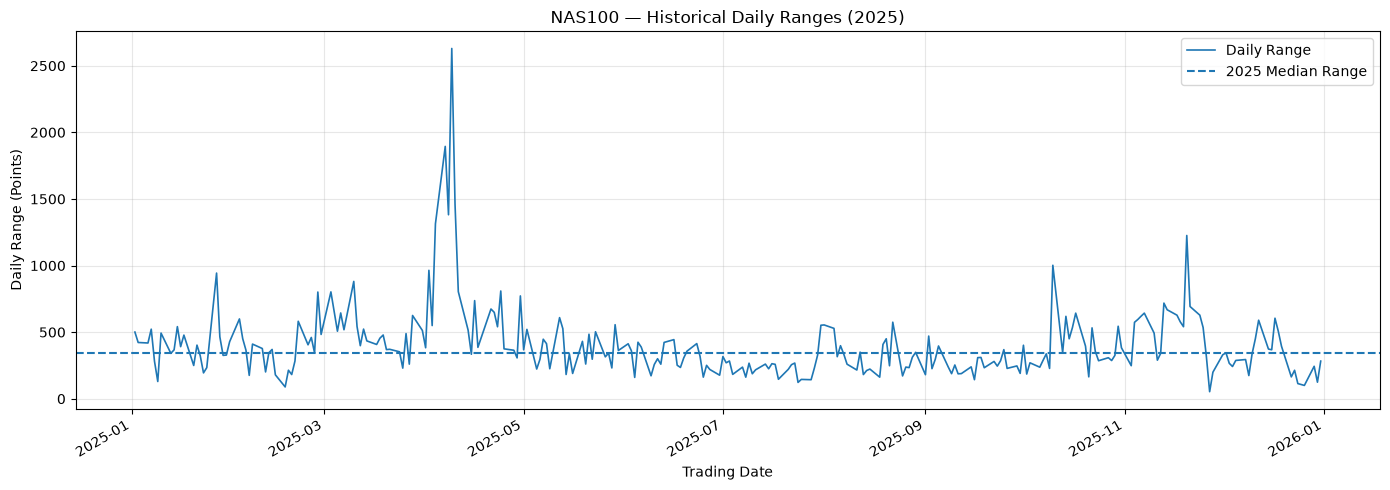

In [19]:

# Step 19 — Visualise historical daily ranges

import matplotlib.pyplot as plt

chart_data = daily_ranges.copy()
chart_data["trading_date"] = pd.to_datetime(
    chart_data["trading_date"]
)

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    chart_data["trading_date"],
    chart_data["range_points"],
    linewidth=1.2,
    label="Daily Range"
)

ax.axhline(
    y=reference_days["range_points"].median(),
    linestyle="--",
    linewidth=1.5,
    label="2025 Median Range"
)

ax.set_title("NAS100 — Historical Daily Ranges (2025)")
ax.set_xlabel("Trading Date")
ax.set_ylabel("Daily Range (Points)")

ax.grid(True, alpha=0.3)
ax.legend()

fig.autofmt_xdate()
plt.tight_layout()
plt.show()


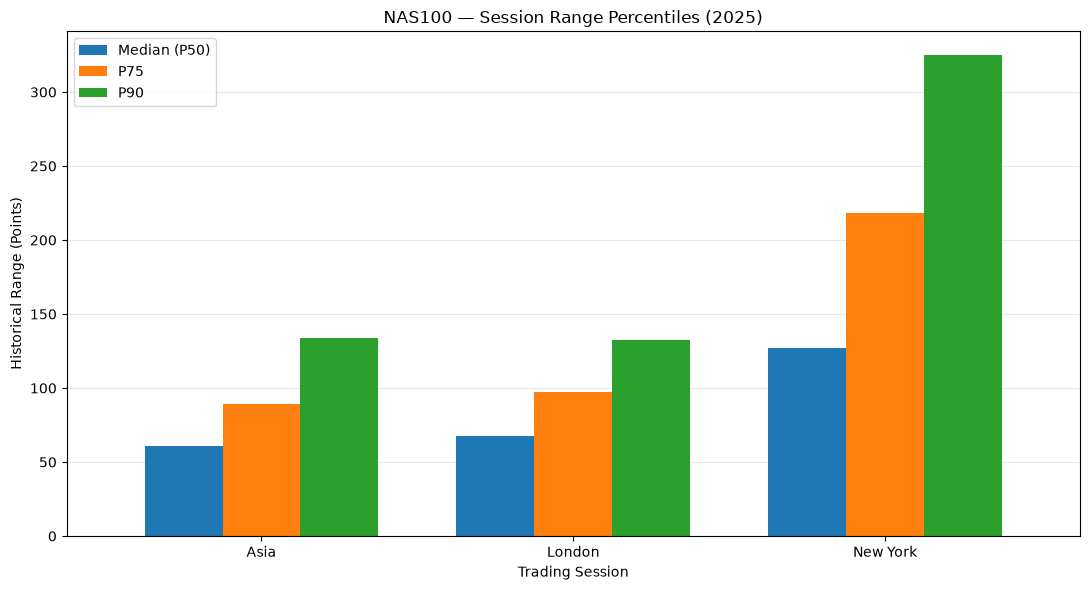

In [20]:

# Step 20 — Visualise historical session range percentiles

sessions = {
    "Asia": asia_reference["range_points"],
    "London": london_reference["range_points"],
    "New York": ny_reference["range_points"],
}

chart_rows = []

for session_name, ranges in sessions.items():
    chart_rows.append({
        "Session": session_name,
        "Median (P50)": ranges.quantile(0.50),
        "P75": ranges.quantile(0.75),
        "P90": ranges.quantile(0.90),
    })

session_chart_data = pd.DataFrame(chart_rows)
session_chart_data = session_chart_data.set_index("Session")

ax = session_chart_data.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.75
)

ax.set_title("NAS100 — Session Range Percentiles (2025)")
ax.set_xlabel("Trading Session")
ax.set_ylabel("Historical Range (Points)")
ax.tick_params(axis="x", rotation=0)

ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


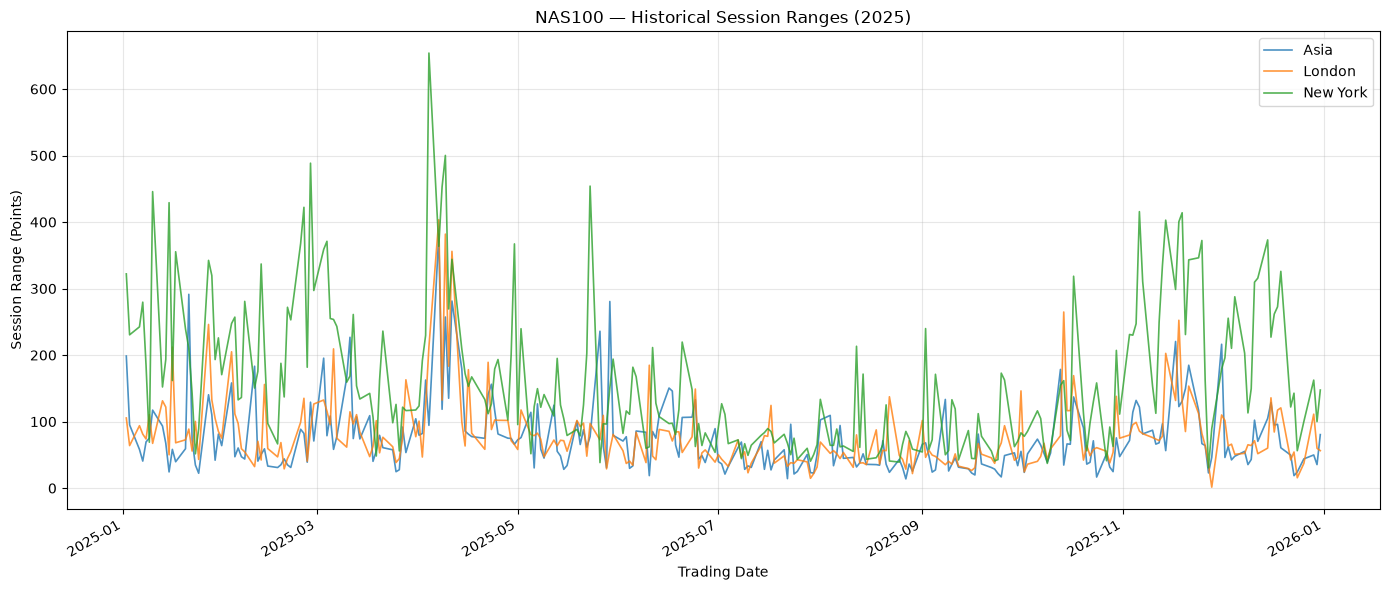

In [21]:

# Step 21 — Historical session ranges over time

fig, ax = plt.subplots(figsize=(14, 6))

session_data = {
    "Asia": asia_ranges,
    "London": london_ranges,
    "New York": ny_ranges,
}

for session_name, session_df in session_data.items():
    dates = pd.to_datetime(session_df["trading_date"])

    ax.plot(
        dates,
        session_df["range_points"],
        linewidth=1.2,
        alpha=0.8,
        label=session_name
    )

ax.set_title("NAS100 — Historical Session Ranges (2025)")
ax.set_xlabel("Trading Date")
ax.set_ylabel("Session Range (Points)")

ax.grid(True, alpha=0.3)
ax.legend()

fig.autofmt_xdate()
plt.tight_layout()
plt.show()


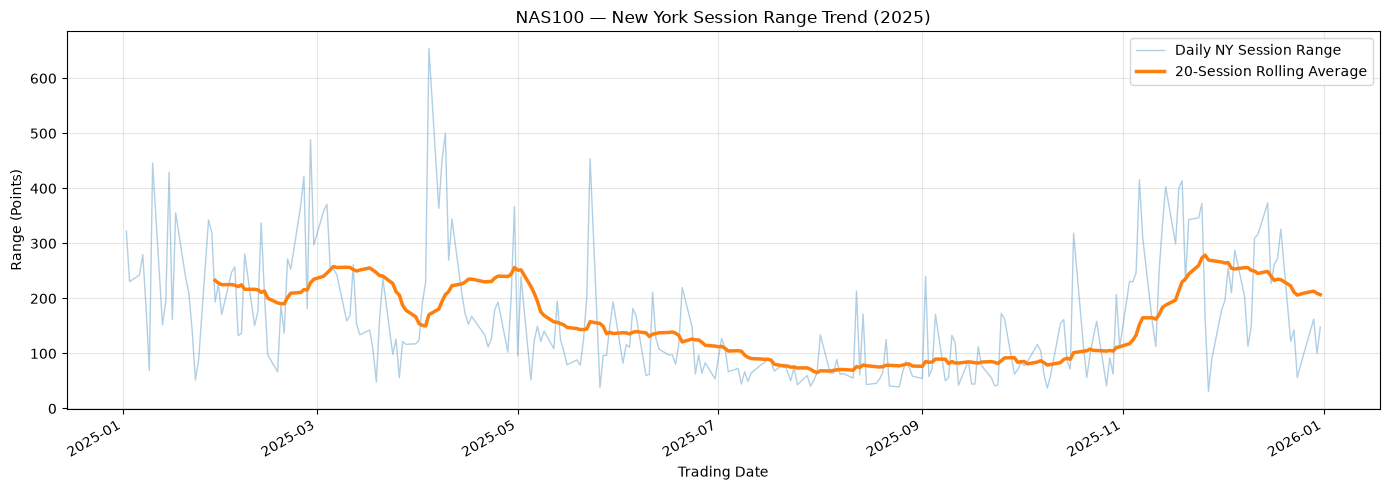

In [22]:

# Step 22 — New York rolling average range

ny_chart = ny_ranges.copy()

ny_chart["trading_date"] = pd.to_datetime(
    ny_chart["trading_date"]
)

ny_chart = ny_chart.sort_values("trading_date")

ny_chart["rolling_20"] = (
    ny_chart["range_points"]
    .rolling(window=20, min_periods=20)
    .mean()
)

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    ny_chart["trading_date"],
    ny_chart["range_points"],
    alpha=0.35,
    linewidth=1,
    label="Daily NY Session Range"
)

ax.plot(
    ny_chart["trading_date"],
    ny_chart["rolling_20"],
    linewidth=2.5,
    label="20-Session Rolling Average"
)

ax.set_title("NAS100 — New York Session Range Trend (2025)")
ax.set_xlabel("Trading Date")
ax.set_ylabel("Range (Points)")

ax.legend()
ax.grid(True, alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()


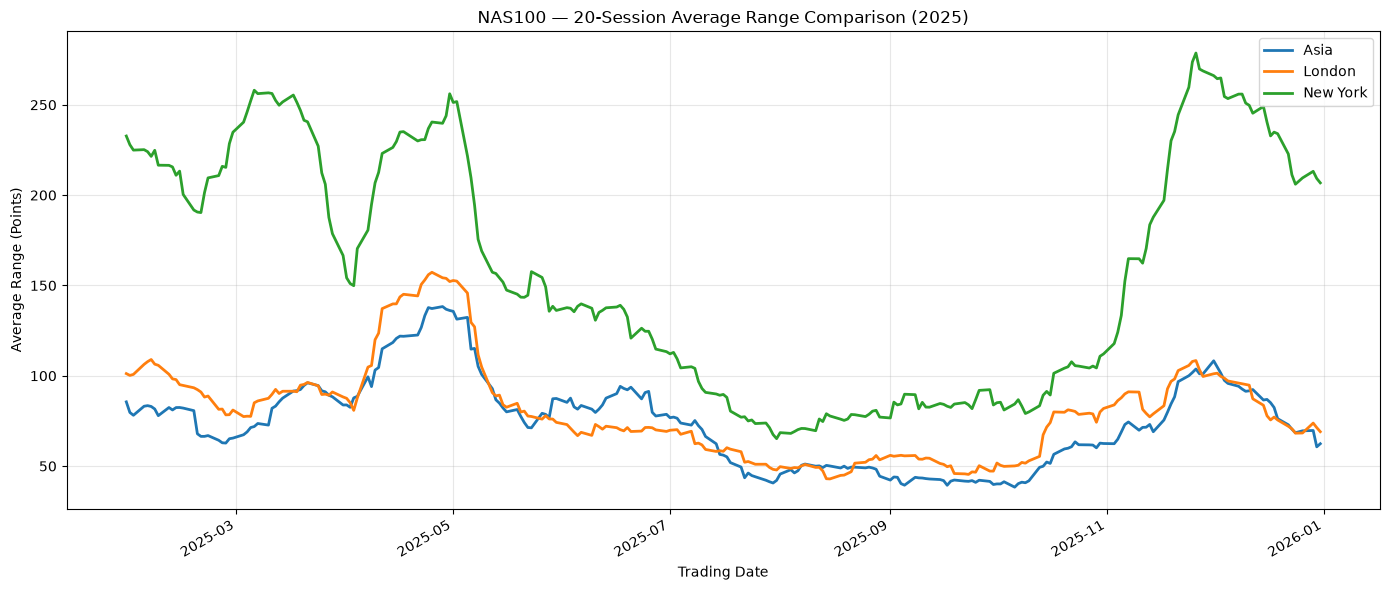

In [23]:

# Step 23 — Compare 20-session rolling average ranges

rolling_sessions = {
    "Asia": asia_ranges,
    "London": london_ranges,
    "New York": ny_ranges,
}

fig, ax = plt.subplots(figsize=(14, 6))

for session_name, session_df in rolling_sessions.items():
    session_chart = session_df.copy()

    session_chart["trading_date"] = pd.to_datetime(
        session_chart["trading_date"]
    )

    session_chart = session_chart.sort_values("trading_date")

    session_chart["rolling_20"] = (
        session_chart["range_points"]
        .rolling(window=20, min_periods=20)
        .mean()
    )

    ax.plot(
        session_chart["trading_date"],
        session_chart["rolling_20"],
        linewidth=2,
        label=session_name
    )

ax.set_title("NAS100 — 20-Session Average Range Comparison (2025)")
ax.set_xlabel("Trading Date")
ax.set_ylabel("Average Range (Points)")

ax.legend()
ax.grid(True, alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()


In [24]:

# Step 24 — Check for duplicate candle timestamps

duplicate_mask = df["datetime"].duplicated(keep=False)

duplicate_candles = df[duplicate_mask].copy()

print("NAS100 — HISTORICAL DATA QUALITY CHECK")
print(f"Total candles: {len(df):,}")
print(f"Duplicate timestamp rows: {len(duplicate_candles):,}")
print(f"Unique timestamps: {df['datetime'].nunique():,}")

if duplicate_candles.empty:
    print("\nSUCCESS: No duplicate candle timestamps found!")
else:
    print("\nWARNING: Duplicate timestamps detected.")
    display(
        duplicate_candles
        .sort_values("datetime")
        .head(20)
    )


NAS100 — HISTORICAL DATA QUALITY CHECK
Total candles: 348,793
Duplicate timestamp rows: 0
Unique timestamps: 348,793

SUCCESS: No duplicate candle timestamps found!


In [25]:

# Step 25 — Identify gaps between candle timestamps

gap_data = df[["datetime"]].copy()

gap_data = gap_data.sort_values("datetime").reset_index(drop=True)

gap_data["previous_candle"] = gap_data["datetime"].shift(1)

gap_data["time_difference"] = (
    gap_data["datetime"] - gap_data["previous_candle"]
)

# Find intervals longer than one minute
gaps = gap_data[
    gap_data["time_difference"] > pd.Timedelta(minutes=1)
].copy()

gaps["gap_minutes"] = (
    gaps["time_difference"].dt.total_seconds() / 60
)

gaps["missing_intervals"] = gaps["gap_minutes"] - 1

print("NAS100 — HISTORICAL CANDLE GAP ANALYSIS (2025)")
print(f"Total candles: {len(df):,}")
print(f"Gaps longer than 1 minute: {len(gaps):,}")

print("\nLargest 15 timestamp gaps:")

display(
    gaps[
        [
            "previous_candle",
            "datetime",
            "gap_minutes",
            "missing_intervals"
        ]
    ]
    .sort_values("gap_minutes", ascending=False)
    .head(15)
)


NAS100 — HISTORICAL CANDLE GAP ANALYSIS (2025)
Total candles: 348,793
Gaps longer than 1 minute: 277

Largest 15 timestamp gaps:


,previous_candle,datetime,gap_minutes,missing_intervals
102830,2025-04-17 23:49:00+00:00,2025-04-21 01:05:00+00:00,4396.0,4395.0
177000,2025-07-04 19:59:00+00:00,2025-07-07 01:05:00+00:00,3186.0,3185.0
318997,2025-11-28 20:14:00+00:00,2025-12-01 01:05:00+00:00,3171.0,3170.0
292795,2025-10-31 23:49:00+00:00,2025-11-03 01:05:00+00:00,2956.0,2955.0
344698,2025-12-26 23:49:00+00:00,2025-12-29 01:05:00+00:00,2956.0,2955.0
339453,2025-12-19 23:49:00+00:00,2025-12-22 01:05:00+00:00,2956.0,2955.0
279145,2025-10-17 23:49:00+00:00,2025-10-20 01:05:00+00:00,2956.0,2955.0
63254,2025-03-07 23:49:00+00:00,2025-03-10 01:05:00+00:00,2956.0,2955.0
285970,2025-10-24 23:49:00+00:00,2025-10-27 01:05:00+00:00,2956.0,2955.0
313270,2025-11-21 23:49:00+00:00,2025-11-24 01:05:00+00:00,2956.0,2955.0


In [26]:

# Step 26 — Investigate intraday timestamp gaps

intraday_gaps = gaps[
    gaps["gap_minutes"] < 1440
].copy()

print("NAS100 — INTRADAY GAP ANALYSIS (2025)")

print(f"Total timestamp gaps: {len(gaps)}")
print(f"Gaps shorter than 24 hours: {len(intraday_gaps)}")

print("\nGap duration distribution:")

gap_distribution = (
    intraday_gaps["gap_minutes"]
    .value_counts()
    .sort_index()
    .rename_axis("gap_minutes")
    .reset_index(name="occurrences")
)

display(gap_distribution)

print("\nLargest 10 gaps shorter than 24 hours:")

display(
    intraday_gaps[
        ["previous_candle", "datetime", "gap_minutes"]
    ]
    .sort_values("gap_minutes", ascending=False)
    .head(10)
)


NAS100 — INTRADAY GAP ANALYSIS (2025)
Total timestamp gaps: 277
Gaps shorter than 24 hours: 224

Gap duration distribution:


,gap_minutes,occurrences
0,2.0,4
1,3.0,3
2,4.0,1
3,5.0,4
4,12.0,1
5,16.0,1
6,19.0,1
7,24.0,1
8,36.0,1
9,48.0,1



Largest 10 gaps shorter than 24 hours:


,previous_candle,datetime,gap_minutes
7750,2025-01-09 16:29:00+00:00,2025-01-10 01:05:00+00:00,516.0
318732,2025-11-28 08:48:00+00:00,2025-11-28 15:50:00+00:00,422.0
44145,2025-02-17 19:59:00+00:00,2025-02-18 01:05:00+00:00,306.0
17075,2025-01-20 19:59:00+00:00,2025-01-21 01:05:00+00:00,306.0
232735,2025-09-01 19:59:00+00:00,2025-09-02 01:05:00+00:00,306.0
318500,2025-11-27 19:59:00+00:00,2025-11-28 01:05:00+00:00,306.0
162430,2025-06-19 19:59:00+00:00,2025-06-20 01:05:00+00:00,306.0
138090,2025-05-26 19:59:00+00:00,2025-05-27 01:05:00+00:00,306.0
175865,2025-07-03 20:14:00+00:00,2025-07-04 01:05:00+00:00,291.0
318730,2025-11-28 06:36:00+00:00,2025-11-28 08:00:00+00:00,84.0


In [27]:

# Step 27 — Investigate recurring 76-minute gaps

regular_gaps = gaps[
    gaps["gap_minutes"] == 76
].copy()

regular_gaps["previous_time_utc"] = (
    regular_gaps["previous_candle"].dt.strftime("%H:%M")
)

regular_gaps["next_time_utc"] = (
    regular_gaps["datetime"].dt.strftime("%H:%M")
)

print("NAS100 — RECURRING 76-MINUTE GAP ANALYSIS")

print(f"Number of occurrences: {len(regular_gaps)}")

print("\nGap start-time distribution (UTC):")
display(
    regular_gaps["previous_time_utc"]
    .value_counts()
    .rename_axis("previous_candle_time")
    .reset_index(name="occurrences")
)

print("\nGap end-time distribution (UTC):")
display(
    regular_gaps["next_time_utc"]
    .value_counts()
    .rename_axis("next_candle_time")
    .reset_index(name="occurrences")
)


NAS100 — RECURRING 76-MINUTE GAP ANALYSIS
Number of occurrences: 196

Gap start-time distribution (UTC):


,previous_candle_time,occurrences
0,23:49,196



Gap end-time distribution (UTC):


,next_candle_time,occurrences
0,01:05,196


In [28]:
# Step 28 — Inspect short, nonstandard timestamp gaps

short_gaps = gaps[
    (gaps["gap_minutes"] > 1) &
    (gaps["gap_minutes"] < 76)
].copy()

print("NAS100 — SHORT TIMESTAMP GAP ANALYSIS (2025)")
print(f"Short gaps found: {len(short_gaps)}")

display(
    short_gaps[
        [
            "previous_candle",
            "datetime",
            "gap_minutes",
            "missing_intervals"
        ]
    ].sort_values("previous_candle")
)

NAS100 — SHORT TIMESTAMP GAP ANALYSIS (2025)
Short gaps found: 18


,previous_candle,datetime,gap_minutes,missing_intervals
53718,2025-02-27 01:22:00+00:00,2025-02-27 01:24:00+00:00,2.0,1.0
65537,2025-03-11 16:22:00+00:00,2025-03-11 16:27:00+00:00,5.0,4.0
65653,2025-03-11 18:22:00+00:00,2025-03-11 18:27:00+00:00,5.0,4.0
87797,2025-04-02 23:30:00+00:00,2025-04-02 23:32:00+00:00,2.0,1.0
318678,2025-11-28 04:02:00+00:00,2025-11-28 04:04:00+00:00,2.0,1.0
318720,2025-11-28 04:45:00+00:00,2025-11-28 04:48:00+00:00,3.0,2.0
318721,2025-11-28 04:48:00+00:00,2025-11-28 04:52:00+00:00,4.0,3.0
318722,2025-11-28 04:52:00+00:00,2025-11-28 04:57:00+00:00,5.0,4.0
318723,2025-11-28 04:57:00+00:00,2025-11-28 05:00:00+00:00,3.0,2.0
318724,2025-11-28 05:00:00+00:00,2025-11-28 05:16:00+00:00,16.0,15.0


In [29]:

# Step 29 — Inspect short gaps outside Thanksgiving Friday

regular_day_gaps = short_gaps[
    short_gaps["previous_candle"].dt.date
    != pd.Timestamp("2025-11-28").date()
].copy()

print("NAS100 — NON-HOLIDAY SHORT GAP INVESTIGATION")

print(f"Short gaps outside 28 November: {len(regular_day_gaps)}")

display(
    regular_day_gaps[
        [
            "previous_candle",
            "datetime",
            "gap_minutes",
            "missing_intervals"
        ]
    ].sort_values("previous_candle")
)


NAS100 — NON-HOLIDAY SHORT GAP INVESTIGATION
Short gaps outside 28 November: 6


,previous_candle,datetime,gap_minutes,missing_intervals
53718,2025-02-27 01:22:00+00:00,2025-02-27 01:24:00+00:00,2.0,1.0
65537,2025-03-11 16:22:00+00:00,2025-03-11 16:27:00+00:00,5.0,4.0
65653,2025-03-11 18:22:00+00:00,2025-03-11 18:27:00+00:00,5.0,4.0
87797,2025-04-02 23:30:00+00:00,2025-04-02 23:32:00+00:00,2.0,1.0
333474,2025-12-15 14:51:00+00:00,2025-12-15 15:10:00+00:00,19.0,18.0
333475,2025-12-15 15:10:00+00:00,2025-12-15 15:12:00+00:00,2.0,1.0


In [30]:

# Step 30 — Validate historical candle timestamp ordering

print("NAS100 — TIMESTAMP ORDER VALIDATION")

timestamps = df["datetime"]

is_sorted = timestamps.is_monotonic_increasing

backward_moves = (
    timestamps.diff() < pd.Timedelta(0)
).sum()

print(f"Timestamps correctly ordered: {is_sorted}")
print(f"Backward timestamp movements: {backward_moves}")

if is_sorted and backward_moves == 0:
    print("\nSUCCESS: Candle timestamps are chronologically ordered!")
else:
    print("\nWARNING: Timestamp ordering requires investigation.")


NAS100 — TIMESTAMP ORDER VALIDATION
Timestamps correctly ordered: True
Backward timestamp movements: 0

SUCCESS: Candle timestamps are chronologically ordered!


In [31]:

# Step 31 — Consolidated historical data-quality report

from src.data_quality import (
    validate_timestamps,
    detect_candle_gaps,
    classify_candle_gaps,
)

# Validate the full dataset.
timestamp_report = validate_timestamps(df)

# Detect gaps and classify their patterns.
detected_gaps = detect_candle_gaps(df)
classified_gaps = classify_candle_gaps(detected_gaps)

print("NAS100 — HISTORICAL DATA QUALITY REPORT")
print("=" * 45)

print("\nTIMESTAMP VALIDATION")
for key, value in timestamp_report.items():
    print(f"{key}: {value}")

print("\nGAP CLASSIFICATION")
display(
    classified_gaps["gap_classification"]
    .value_counts()
    .rename_axis("classification")
    .reset_index(name="occurrences")
)

print("\nTOTAL GAPS:", len(classified_gaps))


NAS100 — HISTORICAL DATA QUALITY REPORT

TIMESTAMP VALIDATION
total_candles: 348793
unique_timestamps: 348793
duplicate_rows: 0
is_chronologically_sorted: True
backward_movements: 0

GAP CLASSIFICATION


,classification,occurrences
0,recurring_break_pattern,196
1,extended_gap_review,63
2,short_gap_review,18



TOTAL GAPS: 277


In [32]:

# Step 32 — Map gaps requiring review to trading dates

review_gaps = classified_gaps[
    classified_gaps["gap_classification"].isin([
        "short_gap_review",
        "extended_gap_review"
    ])
].copy()

# Use the UTC date of the candle before each gap.
review_gaps["trading_date"] = (
    review_gaps["previous_candle"].dt.date
)

daily_gap_summary = (
    review_gaps
    .groupby("trading_date")
    .agg(
        flagged_gaps=("gap_classification", "size"),
        total_gap_minutes=("gap_minutes", "sum")
    )
    .reset_index()
)

print("NAS100 — DATES WITH GAPS REQUIRING REVIEW")
print(f"Dates flagged: {len(daily_gap_summary)}")

display(daily_gap_summary.head(20))


NAS100 — DATES WITH GAPS REQUIRING REVIEW
Dates flagged: 65


,trading_date,flagged_gaps,total_gap_minutes
0,2025-01-03,1,2956.0
1,2025-01-09,1,516.0
2,2025-01-10,1,2956.0
3,2025-01-17,1,2956.0
4,2025-01-20,1,306.0
5,2025-01-24,1,2956.0
6,2025-01-31,1,2956.0
7,2025-02-07,1,2956.0
8,2025-02-14,1,2956.0
9,2025-02-17,1,306.0


In [33]:

# Step 33 — Identify Friday-to-Monday weekend gaps

gap_review = classified_gaps.copy()

previous = gap_review["previous_candle"]
current = gap_review["datetime"]

weekend_pattern = (
    (previous.dt.dayofweek == 4)
    & (current.dt.dayofweek == 0)
    & (current.dt.normalize() - previous.dt.normalize()
       == pd.Timedelta(days=3))
)

gap_review["is_weekend_pattern"] = weekend_pattern

print("NAS100 — WEEKEND GAP INVESTIGATION")

print(
    "Friday-to-Monday gaps:",
    int(gap_review["is_weekend_pattern"].sum())
)

print(
    "Other gaps:",
    int((~gap_review["is_weekend_pattern"]).sum())
)

display(
    gap_review.loc[
        gap_review["is_weekend_pattern"],
        ["previous_candle", "datetime", "gap_minutes"]
    ].head(10)
)


NAS100 — WEEKEND GAP INVESTIGATION
Friday-to-Monday gaps: 51
Other gaps: 226


,previous_candle,datetime,gap_minutes
1,2025-01-03 23:49:00+00:00,2025-01-06 01:05:00+00:00,2956.0
6,2025-01-10 23:49:00+00:00,2025-01-13 01:05:00+00:00,2956.0
11,2025-01-17 23:49:00+00:00,2025-01-20 01:05:00+00:00,2956.0
16,2025-01-24 23:49:00+00:00,2025-01-27 01:05:00+00:00,2956.0
21,2025-01-31 23:49:00+00:00,2025-02-03 01:05:00+00:00,2956.0
26,2025-02-07 23:49:00+00:00,2025-02-10 01:05:00+00:00,2956.0
31,2025-02-14 23:49:00+00:00,2025-02-17 01:05:00+00:00,2956.0
36,2025-02-21 23:49:00+00:00,2025-02-24 01:05:00+00:00,2956.0
42,2025-02-28 23:49:00+00:00,2025-03-03 01:05:00+00:00,2956.0
47,2025-03-07 23:49:00+00:00,2025-03-10 01:05:00+00:00,2956.0


In [34]:

# Step 34 — Investigate non-weekend gap classifications

non_weekend_gaps = gap_review[
    ~gap_review["is_weekend_pattern"]
].copy()

summary = (
    non_weekend_gaps["gap_classification"]
    .value_counts()
    .rename_axis("classification")
    .reset_index(name="occurrences")
)

print("NAS100 — NON-WEEKEND GAP CLASSIFICATIONS")
print(f"Total non-weekend gaps: {len(non_weekend_gaps)}")

display(summary)

print("\nEXTENDED GAPS NOT MATCHING FRIDAY-TO-MONDAY")

display(
    non_weekend_gaps[
        non_weekend_gaps["gap_classification"]
        == "extended_gap_review"
    ][
        ["previous_candle", "datetime", "gap_minutes"]
    ].sort_values("previous_candle")
)


NAS100 — NON-WEEKEND GAP CLASSIFICATIONS
Total non-weekend gaps: 226


,classification,occurrences
0,recurring_break_pattern,196
1,short_gap_review,18
2,extended_gap_review,12



EXTENDED GAPS NOT MATCHING FRIDAY-TO-MONDAY


,previous_candle,datetime,gap_minutes
5,2025-01-09 16:29:00+00:00,2025-01-10 01:05:00+00:00,516.0
12,2025-01-20 19:59:00+00:00,2025-01-21 01:05:00+00:00,306.0
32,2025-02-17 19:59:00+00:00,2025-02-18 01:05:00+00:00,306.0
79,2025-04-17 23:49:00+00:00,2025-04-21 01:05:00+00:00,4396.0
105,2025-05-26 19:59:00+00:00,2025-05-27 01:05:00+00:00,306.0
123,2025-06-19 19:59:00+00:00,2025-06-20 01:05:00+00:00,306.0
133,2025-07-03 20:14:00+00:00,2025-07-04 01:05:00+00:00,291.0
175,2025-09-01 19:59:00+00:00,2025-09-02 01:05:00+00:00,306.0
238,2025-11-27 19:59:00+00:00,2025-11-28 01:05:00+00:00,306.0
250,2025-11-28 06:36:00+00:00,2025-11-28 08:00:00+00:00,84.0


In [35]:

# Step 35 — Examine non-weekend extended gaps

extended_review = non_weekend_gaps[
    non_weekend_gaps["gap_classification"]
    == "extended_gap_review"
].copy()

extended_review["previous_weekday"] = (
    extended_review["previous_candle"].dt.day_name()
)

extended_review["next_weekday"] = (
    extended_review["datetime"].dt.day_name()
)

extended_review["previous_date"] = (
    extended_review["previous_candle"].dt.date
)

extended_review["next_date"] = (
    extended_review["datetime"].dt.date
)

print("NAS100 — EXTENDED GAP INVESTIGATION (2025)")
print(f"Extended gaps: {len(extended_review)}")

display(
    extended_review[
        [
            "previous_date",
            "previous_weekday",
            "next_date",
            "next_weekday",
            "gap_minutes"
        ]
    ]
)


NAS100 — EXTENDED GAP INVESTIGATION (2025)
Extended gaps: 12


,previous_date,previous_weekday,next_date,next_weekday,gap_minutes
5,2025-01-09,Thursday,2025-01-10,Friday,516.0
12,2025-01-20,Monday,2025-01-21,Tuesday,306.0
32,2025-02-17,Monday,2025-02-18,Tuesday,306.0
79,2025-04-17,Thursday,2025-04-21,Monday,4396.0
105,2025-05-26,Monday,2025-05-27,Tuesday,306.0
123,2025-06-19,Thursday,2025-06-20,Friday,306.0
133,2025-07-03,Thursday,2025-07-04,Friday,291.0
175,2025-09-01,Monday,2025-09-02,Tuesday,306.0
238,2025-11-27,Thursday,2025-11-28,Friday,306.0
250,2025-11-28,Friday,2025-11-28,Friday,84.0


In [36]:

# Step 36 — Investigate November 28 extended gaps

november_gaps = extended_review[
    extended_review["previous_candle"].dt.date
    == pd.Timestamp("2025-11-28").date()
].copy()

november_gaps["start_utc"] = (
    november_gaps["previous_candle"].dt.strftime("%H:%M")
)

november_gaps["end_utc"] = (
    november_gaps["datetime"].dt.strftime("%H:%M")
)

print("NAS100 — 28 NOVEMBER 2025 GAP INVESTIGATION")

display(
    november_gaps[
        [
            "previous_candle",
            "datetime",
            "start_utc",
            "end_utc",
            "gap_minutes"
        ]
    ]
)


NAS100 — 28 NOVEMBER 2025 GAP INVESTIGATION


,previous_candle,datetime,start_utc,end_utc,gap_minutes
250,2025-11-28 06:36:00+00:00,2025-11-28 08:00:00+00:00,06:36,08:00,84.0
252,2025-11-28 08:48:00+00:00,2025-11-28 15:50:00+00:00,08:48,15:50,422.0


In [37]:

# Step 37 — Inspect November 28 hourly candle coverage

selected_date = pd.Timestamp("2025-11-28").date()

day_data = df[
    df["datetime"].dt.date == selected_date
].copy()

day_data["hour_utc"] = df.loc[
    day_data.index, "datetime"
].dt.hour

hourly_coverage = (
    day_data.groupby("hour_utc")
    .size()
    .reset_index(name="candle_count")
)

print("NAS100 — 28 NOVEMBER 2025 HOURLY COVERAGE")
print(f"Total candles: {len(day_data)}")

display(hourly_coverage)


NAS100 — 28 NOVEMBER 2025 HOURLY COVERAGE
Total candles: 497


,hour_utc,candle_count
0,1,55
1,2,60
2,3,60
3,4,48
4,5,4
5,6,3
6,8,2
7,15,10
8,16,60
9,17,60


In [38]:
# Step 38 — Compare an unusual day against historical ranges

selected_date = pd.Timestamp("2025-11-28").date()

selected_day = daily_ranges[
    daily_ranges["trading_date"] == selected_date
]

print("NAS100 — UNUSUAL TRADING DAY COMPARISON")

display(
    selected_day[
        [
            "trading_date",
            "high",
            "low",
            "range_points",
            "range_percent",
            "candle_count",
            "coverage_status"
        ]
    ]
)

print("\n2025 REFERENCE-COVERAGE BENCHMARKS")
print(f"Median daily range: {reference_days['range_points'].median():.2f} pts")
print(f"P25 daily range: {reference_days['range_points'].quantile(0.25):.2f} pts")
print(f"P75 daily range: {reference_days['range_points'].quantile(0.75):.2f} pts")

NAS100 — UNUSUAL TRADING DAY COMPARISON


,trading_date,high,low,range_points,range_percent,candle_count,coverage_status
235,2025-11-28,25443.35,25244.06,199.29,0.7895,497,reduced_coverage



2025 REFERENCE-COVERAGE BENCHMARKS
Median daily range: 346.29 pts
P25 daily range: 247.04 pts
P75 daily range: 493.10 pts
